# Task 1 EDA: `handicaps` in Link-Lives Release 2 (1801, 1850, 1860, 1880, 1901)

**Scope.** This notebook describes what the data shows. It decides nothing: the Task 1 method, whether to use an LLM for categories, the embedding scope and the File B impact definition are decisions I made after this EDA (see the closing section "Facts for open decisions").

**Data handling.** Only aggregates, distributions, plots and value-frequency tables are displayed. No record-level rows are shown: no `pa_id` or other identifier columns, no names next to other attributes, no raw-frame previews. All columns are stored as strings in the parquet files, so numeric readings below are explicit casts that report their parse failures.

**Reading rule.** An empty `handicaps` value is not evidence of "no handicap". It may mean the question was not asked or the value was not transcribed. Column descriptions below describe what the data shows, not official definitions; the Link-Lives Release 2 Guide is the authority.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display
from rapidfuzz import fuzz, process

# nbconvert runs the kernel in the notebook's directory, so scripts/ is one level up.
sys.path.insert(0, str(Path.cwd().resolve().parent / "scripts"))
import project_paths as pp

pl.Config.set_tbl_rows(60)
pl.Config.set_fmt_str_lengths(80)

YEARS = pp.CENSUS_YEARS
LF = {y: pl.scan_parquet(pp.census_parquet(y)) for y in YEARS}
MIN_EXAMPLE_COUNT = 5
CAPACITY_LINES = (200, 300, 360)
CLUSTER_THRESHOLDS = (80, 85, 90)
REF_THRESHOLD = 85
FACTS = {}


def filled(col):
    # Not null and not blank after strip.
    return pl.col(col).is_not_null() & (pl.col(col).str.strip_chars() != "")


def trivial_norm(expr):
    # lowercase, punctuation runs -> space, collapse whitespace, strip.
    return (
        expr.str.to_lowercase()
        .str.replace_all(r"[^\w\s]+", " ")
        .str.replace_all(r"\s+", " ")
        .str.strip_chars()
    )


def fact(key, value):
    if isinstance(value, float):
        value = round(value, 4)
    FACTS[key] = value
    print(f"FACT {key}={value}")


def safe_div(a, b):
    return a / b if b else 0.0

## 1. `handicaps` per census year

In [2]:
def year_summary(y):
    row = (
        LF[y]
        .select(
            pl.len().alias("rows_n"),
            filled("handicaps").sum().alias("filled_n"),
            pl.col("handicaps").filter(filled("handicaps")).n_unique().alias("raw_distinct_n"),
        )
        .collect()
        .row(0, named=True)
    )
    row["year"] = y
    row["fill_rate"] = safe_div(row["filled_n"], row["rows_n"])
    return row


summary = pl.DataFrame([year_summary(y) for y in YEARS]).select(
    "year", "rows_n", "filled_n", "fill_rate", "raw_distinct_n"
)
for r in summary.iter_rows(named=True):
    fact(f"task1.rows.{r['year']}", r["rows_n"])
    fact(f"task1.fill_rate.{r['year']}", r["fill_rate"])
    fact(f"task1.raw_distinct.{r['year']}", r["raw_distinct_n"])
summary

FACT task1.rows.1801=937944
FACT task1.fill_rate.1801=0.0001
FACT task1.raw_distinct.1801=2
FACT task1.rows.1850=1405217
FACT task1.fill_rate.1850=0.0094
FACT task1.raw_distinct.1850=1832
FACT task1.rows.1860=1748226
FACT task1.fill_rate.1860=0.0123
FACT task1.raw_distinct.1860=1300
FACT task1.rows.1880=1979455
FACT task1.fill_rate.1880=0.0243
FACT task1.raw_distinct.1880=855
FACT task1.rows.1901=2468040
FACT task1.fill_rate.1901=0.0246
FACT task1.raw_distinct.1901=880


year,rows_n,filled_n,fill_rate,raw_distinct_n
i64,i64,i64,f64,i64
1801,937944,86,0.000092,2
1850,1405217,13144,0.009354,1832
1860,1748226,21575,0.012341,1300
1880,1979455,48011,0.024255,855
1901,2468040,60781,0.024627,880


**Caveat next to these numbers.** "Missing" here means null or blank after stripping whitespace. An empty `handicaps` value may mean the question was not asked or the value was not transcribed; it must not be read as "no handicap". `raw_distinct_n` counts distinct filled strings exactly as stored. Years with very few filled values are shown as they are, and all rates are zero-safe.

## 2. Column overview (what the data shows)

Storage is all-String by design, so "type" below is an **observed parse profile**, not an official type: `int_parse_share` is the share of filled values that parse as a whole number (an explicit integer cast, or a float cast with no fractional part, because numbers such as ages are stored like "34.0"), and a column is labelled "integer-like" when that share is at least 0.95, otherwise "text". `pct_missing` counts null or blank values (in percent). `n_unique` counts distinct filled values. `examples` lists up to three values that occur at least `MIN_EXAMPLE_COUNT` times, with their counts. Identifier columns, free-text columns and name columns are masked as "(not shown)".

These descriptions say what the columns contain in this data. Their meanings are **not** asserted here: the Release 2 Guide is the authority.

In [3]:
MASK_EXAMPLE_COLUMNS = {
    "pa_id", "Indtastningsnr", "løbenr_i_indtastning", "Kildehenvisning",
    "Husstands_familienr", "Matr_nr_adresse", "Adresse", "Matrikel", "gadenr",
    "fødselsdato", "Kommentarer", "kildekommentar", "source_id",
    # name columns are masked too: names are never displayed
    "navn", "ejernavn", "ejendom_navn",
}


def whole_number(expr):
    # explicit casts on the stripped string; "34.0" counts as whole, "34.5" and "abc" do not
    f = expr.cast(pl.Float64, strict=False)
    return f.is_not_null() & f.is_finite() & (f == f.floor())


def column_profile(lf, col, rows_n, mask):
    vc = (
        lf.select(pl.col(col).str.strip_chars().alias("v"))
        .filter(pl.col("v").is_not_null() & (pl.col("v") != ""))
        .group_by("v")
        .len()
        .rename({"len": "n"})
        .collect()
    )
    filled_n = int(vc["n"].sum()) if vc.height else 0
    int_n = (
        int(vc.filter(whole_number(pl.col("v")))["n"].sum())
        if vc.height
        else 0
    )
    int_share = safe_div(int_n, filled_n)
    if mask:
        examples = "(not shown)"
    else:
        top = (
            vc.filter(pl.col("n") >= MIN_EXAMPLE_COUNT)
            .sort(["n", "v"], descending=[True, False])
            .head(3)
        )
        examples = "; ".join(f"{v} ({n})" for v, n in top.iter_rows())
    return {
        "column": col,
        "type_profile": "integer-like" if int_share >= 0.95 else "text",
        "int_parse_share": round(int_share, 4),
        "pct_missing": round(100 * (1 - safe_div(filled_n, rows_n)), 2),
        "n_unique": vc.height,
        "examples": examples,
    }


def column_overview(lf, year):
    rows_n = lf.select(pl.len()).collect().item()
    cols = lf.collect_schema().names()
    return pl.DataFrame(
        [column_profile(lf, c, rows_n, c in MASK_EXAMPLE_COLUMNS) for c in cols],
        schema={
            "column": pl.String, "type_profile": pl.String, "int_parse_share": pl.Float64,
            "pct_missing": pl.Float64, "n_unique": pl.UInt32, "examples": pl.String,
        },
    )


def alder_tal_findings(lf):
    # explicit cast of filled alder_tal: not numeric at all, or numeric with a fractional part
    vc = (
        lf.select(pl.col("alder_tal").str.strip_chars().alias("v"))
        .filter(pl.col("v").is_not_null() & (pl.col("v") != ""))
        .group_by("v").len().rename({"len": "n"}).collect()
    )
    if not vc.height:
        return 0, 0
    f = pl.col("v").cast(pl.Float64, strict=False)
    not_numeric = int(vc.filter(f.is_null() | f.is_nan() | f.is_infinite())["n"].sum())
    fractional = int(vc.filter(f.is_finite() & (f != f.floor()))["n"].sum())
    return not_numeric, fractional


OVERVIEW = {}
for y in YEARS:
    OVERVIEW[y] = column_overview(LF[y], y)
    bad, frac = alder_tal_findings(LF[y])
    fact(f"task1.alder_tal_parse_fail.{y}", bad)
    fact(f"task1.alder_tal_fractional.{y}", frac)

FACT task1.alder_tal_parse_fail.1801=0
FACT task1.alder_tal_fractional.1801=18


FACT task1.alder_tal_parse_fail.1850=0
FACT task1.alder_tal_fractional.1850=592


FACT task1.alder_tal_parse_fail.1860=0
FACT task1.alder_tal_fractional.1860=257


FACT task1.alder_tal_parse_fail.1880=0
FACT task1.alder_tal_fractional.1880=40074


FACT task1.alder_tal_parse_fail.1901=0
FACT task1.alder_tal_fractional.1901=1


### Column overview 1801

In [4]:
OVERVIEW[1801]

column,type_profile,int_parse_share,pct_missing,n_unique,examples
str,str,f64,f64,u32,str
"""pa_id""","""integer-like""",1.0,0.0,937944,"""(not shown)"""
"""Indtastningsnr""","""text""",0.0,0.0,1796,"""(not shown)"""
"""Kilde""","""text""",0.0004,0.0,6,"""FT-1801 (898179); FT 1801 (36196); Vz-1801 (2093)"""
"""løbenr_i_indtastning""","""integer-like""",1.0,0.0,15369,"""(not shown)"""
"""Kildehenvisning""","""text""",0.6217,4.53,5947,"""(not shown)"""
"""Stednavn""","""text""",0.0001,2.06,15431,"""Hof- & Militæretaten (15362); Sankt Annæ Vester Kvarter (14553); Christianshavns…"
"""Husstands_familienr""","""text""",0.8374,0.19,11412,"""(not shown)"""
"""Matr_nr_adresse""","""text""",0.1087,68.02,11898,"""(not shown)"""
"""navn""","""text""",0.0001,0.0,248709,"""(not shown)"""


### Column overview 1850

In [5]:
OVERVIEW[1850]

column,type_profile,int_parse_share,pct_missing,n_unique,examples
str,str,f64,f64,u32,str
"""pa_id""","""integer-like""",1.0,0.0,1405217,"""(not shown)"""
"""Indtastningsnr""","""text""",0.0,0.0,1790,"""(not shown)"""
"""Kilde""","""text""",0.0,0.0,2,"""FT-1850 (1392074); FT 1850 (13143)"""
"""løbenr_i_indtastning""","""integer-like""",1.0,0.0,22479,"""(not shown)"""
"""Kildehenvisning""","""text""",0.645,0.92,5230,"""(not shown)"""
"""Stednavn""","""text""",0.0,2.18,15342,"""Odense Kiøbstad (11126); Købmager kvarter (7754); Adelgade (6232)"""
"""Husstands_familienr""","""text""",0.8401,2.78,16077,"""(not shown)"""
"""Matr_nr_adresse""","""text""",0.0121,6.85,46365,"""(not shown)"""
"""navn""","""text""",0.0,0.0,416375,"""(not shown)"""


### Column overview 1860

In [6]:
OVERVIEW[1860]

column,type_profile,int_parse_share,pct_missing,n_unique,examples
str,str,f64,f64,u32,str
"""pa_id""","""integer-like""",1.0,0.0,1748226,"""(not shown)"""
"""Indtastningsnr""","""text""",0.0,0.0,1930,"""(not shown)"""
"""Kilde""","""text""",0.0011,0.0,5,"""FT-1860 (1742668); FT 1860 (2849); 1860 (1855)"""
"""løbenr_i_indtastning""","""integer-like""",1.0,0.0,32947,"""(not shown)"""
"""Kildehenvisning""","""text""",0.2847,1.87,13955,"""(not shown)"""
"""Stednavn""","""text""",0.0,1.08,19487,"""St Anne Vester (17931); Udenbys Klædebo Kvarter (16422); Sankt Annæ Vester (1498…"
"""Husstands_familienr""","""text""",0.7817,0.34,33934,"""(not shown)"""
"""Matr_nr_adresse""","""text""",0.0048,10.16,38008,"""(not shown)"""
"""navn""","""text""",0.0,0.0,597863,"""(not shown)"""


### Column overview 1880

In [7]:
OVERVIEW[1880]

column,type_profile,int_parse_share,pct_missing,n_unique,examples
str,str,f64,f64,u32,str
"""pa_id""","""integer-like""",1.0,0.0,1979455,"""(not shown)"""
"""Indtastningsnr""","""text""",0.0,0.0,2202,"""(not shown)"""
"""Kilde""","""text""",0.0,0.0,5,"""FT-1880 (1975874); FT1880 (1815); FT 1880 (991)"""
"""løbenr_i_indtastning""","""integer-like""",0.9999,0.0,25286,"""(not shown)"""
"""Kildehenvisning""","""text""",0.1452,2.29,28462,"""(not shown)"""
"""Stednavn""","""text""",0.0008,1.17,24066,"""Odense Kjøbstad (21017); Horsens Købstad (12671); Udenbys Klædebo Kvarter (9834)"""
"""Husstands_familienr""","""text""",0.8347,2.5,39222,"""(not shown)"""
"""Matr_nr_adresse""","""text""",0.0006,12.28,73145,"""(not shown)"""
"""navn""","""text""",0.0,0.0,860142,"""(not shown)"""


### Column overview 1901

In [8]:
OVERVIEW[1901]

column,type_profile,int_parse_share,pct_missing,n_unique,examples
str,str,f64,f64,u32,str
"""pa_id""","""integer-like""",1.0,0.0,2468040,"""(not shown)"""
"""Indtastningsnr""","""text""",0.0,0.0,2789,"""(not shown)"""
"""Kilde""","""text""",0.0,0.0,2,"""FT-1901 (2467394); FT1901 (646)"""
"""løbenr_i_indtastning""","""integer-like""",1.0,0.0,52447,"""(not shown)"""
"""Kildehenvisning""","""text""",0.0553,0.49,30312,"""(not shown)"""
"""Stednavn""","""text""",0.0001,36.6,13176,"""- (52005); Lyngby (5278); Varde Købstad (4833)"""
"""Husstands_familienr""","""integer-like""",0.955,0.44,23177,"""(not shown)"""
"""Matr_nr_adresse""","""text""",0.2774,50.14,21141,"""(not shown)"""
"""navn""","""text""",0.0,0.0,1159612,"""(not shown)"""


`task1.alder_tal_parse_fail.<year>` above counts filled `alder_tal` values that do not parse as a number at all, and `task1.alder_tal_fractional.<year>` those that parse but have a fractional part. Both are findings about the data, not corrected. Note that `alder_tal` is stored in a float format (for example "34.0"), so a plain integer cast would reject nearly every value; the explicit cast therefore goes through a float and then checks for a whole number.

## 3. Missingness by geography

The geographic unit is the **parish key** `Amt|Herred|Sogn`, built as a composite because parish names repeat across counties and districts. For each year, a unit is **empty** when none of its records has a filled `handicaps` value. Records with no geography at all are left out of the unit counts and reported separately as `no_geo_rows_n`.

In [9]:
GEO = ["Amt", "Herred", "Sogn"]


def geo_key():
    parts = [pl.when(filled(c)).then(pl.col(c).str.strip_chars()) for c in GEO]
    return pl.concat_str(parts, separator="|", ignore_nulls=True)


def parish_summary(y):
    per_unit = (
        LF[y]
        .select(geo_key().alias("key"), filled("handicaps").alias("h"))
        .filter(pl.col("key") != "")
        .group_by("key")
        .agg(pl.col("h").sum().alias("filled_n"))
        .collect()
    )
    units_n = per_unit.height
    empty_n = int(per_unit.filter(pl.col("filled_n") == 0).height)
    no_geo = (
        LF[y].select((geo_key() == "").sum().alias("n")).collect().item()
    )
    return {
        "year": y,
        "units_n": units_n,
        "empty_units_n": empty_n,
        "empty_unit_share": safe_div(empty_n, units_n),
        "no_geo_rows_n": int(no_geo),
    }


parish_table = pl.DataFrame([parish_summary(y) for y in YEARS])
for r in parish_table.iter_rows(named=True):
    fact(f"task1.empty_parish_share.{r['year']}", r["empty_unit_share"])
parish_table

FACT task1.empty_parish_share.1801=0.9994
FACT task1.empty_parish_share.1850=0.4304
FACT task1.empty_parish_share.1860=0.3
FACT task1.empty_parish_share.1880=0.3011
FACT task1.empty_parish_share.1901=0.3103


year,units_n,empty_units_n,empty_unit_share,no_geo_rows_n
i64,i64,i64,f64,i64
1801,1796,1795,0.999443,0
1850,1789,770,0.430408,0
1860,1930,579,0.3,0
1880,2202,663,0.30109,0
1901,2788,865,0.310258,0


**Caveat next to these numbers.** A parish with no filled values suggests "not asked / not transcribed" rather than "no handicap". 1801 is the clearest case: almost every parish is empty, which points at the source or the transcription, not at an absence of handicaps. A parish with a filled share is not evidence of completeness either.

In [10]:
def fill_by_amt(y):
    return (
        LF[y]
        .select(
            pl.when(filled("Amt")).then(pl.col("Amt").str.strip_chars()).otherwise(pl.lit("(missing)")).alias("Amt"),
            filled("handicaps").alias("h"),
        )
        .group_by("Amt")
        .agg((pl.col("h").sum() / pl.len()).alias(str(y)))
        .collect()
    )


amt_pivot = fill_by_amt(YEARS[0])
for y in YEARS[1:]:
    amt_pivot = amt_pivot.join(fill_by_amt(y), on="Amt", how="full", coalesce=True)
amt_pivot = amt_pivot.sort("Amt").with_columns(pl.col(pl.Float64).round(4))
amt_pivot

Amt,1801,1850,1860,1880,1901
str,f64,f64,f64,f64,f64
"""Aabenraa""",null,null,0.0024,null,null
"""Aalborg""",0.0,0.0031,0.0235,0.0026,0.0483
"""Aarhus""",0.0,0.0027,0.0046,0.0991,0.0071
"""Bornholm""",0.0,0.0031,0.0034,0.0035,0.0035
"""Frederiksborg""",0.0,0.0124,0.0036,0.0047,0.0155
"""Haderslev""",0.0,0.3641,0.0113,null,null
"""Hjørring""",0.0,0.0029,0.0047,0.1555,0.0127
"""Holbæk""",0.0,0.0032,0.0206,0.0224,0.1794
"""København""",0.0,0.0169,0.015,0.0194,0.0147


Fill rate by county (`Amt`) across years; a blank cell means the county does not occur in that census. A county whose rate is zero or close to it in one year but not in others again points at "not asked / not transcribed".

## 4. Three-level normalisation preview

Distinct-value counts at three levels: **raw** (filled strings as stored), **trivially normalised** (lowercase, punctuation replaced by a space, whitespace collapsed and stripped), and **rapidfuzz clusters** over the trivially normalised values.

Clustering is greedy leader clustering: values are visited in descending pooled count; each value joins the best leader scoring at least the threshold under `fuzz.ratio`, otherwise it becomes a new leader. Thresholds are `CLUSTER_THRESHOLDS` = 80, 85 and 90; 85 is the loose reference threshold (`REF_THRESHOLD`). **This is a preview only.** The real normalisation is the `harmonise.py` script. `drop_vs_previous_share` is the relative drop against the previous normalisation level; the three cluster settings are alternatives, so each is compared with the trivially normalised level.

In [11]:
# pooled raw value counts per year (value-frequency only)
YEAR_RAW = pl.concat(
    [
        LF[y]
        .select(pl.col("handicaps").alias("raw"))
        .filter(filled("raw"))
        .group_by("raw").len().rename({"len": "n"})
        .with_columns(pl.lit(y).alias("year"))
        .collect()
        for y in YEARS
    ]
).with_columns(trivial_norm(pl.col("raw")).alias("norm"))

POOLED_RAW = YEAR_RAW.group_by("raw").agg(pl.col("n").sum()).sort(["n", "raw"], descending=[True, False])
NORM = (
    YEAR_RAW.group_by("norm")
    .agg(
        pl.col("n").sum().alias("n"),
        pl.col("year").n_unique().alias("years_n"),
        pl.col("raw").n_unique().alias("raw_variants_n"),
    )
    .sort(["n", "norm"], descending=[True, False])
)
TOTAL_FILLED = int(YEAR_RAW["n"].sum())


def leader_clusters(values, threshold):
    # values: iterable sorted by pooled count, descending
    leaders, mapping = [], {}
    for v in values:
        match = process.extractOne(v, leaders, scorer=fuzz.ratio, score_cutoff=threshold) if leaders else None
        if match is None:
            leaders.append(v)
            mapping[v] = v
        else:
            mapping[v] = match[0]
    return mapping, leaders


NORM_VALUES = NORM["norm"].to_list()
CLUSTERS = {t: leader_clusters(NORM_VALUES, t) for t in CLUSTER_THRESHOLDS}

n_raw, n_trivial = POOLED_RAW.height, NORM.height
levels = [("1 raw", n_raw, None), ("2 trivial", n_trivial, safe_div(n_raw - n_trivial, n_raw))]
fact("task1.distinct.raw", n_raw)
fact("task1.distinct.trivial", n_trivial)
fact("task1.drop.trivial_vs_raw", levels[1][2])
for t in CLUSTER_THRESHOLDS:
    n_t = len(CLUSTERS[t][1])
    drop = safe_div(n_trivial - n_t, n_trivial)
    levels.append((f"3 cluster ratio {t}", n_t, drop))
    fact(f"task1.clusters.ratio{t}", n_t)
    fact(f"task1.drop.ratio{t}_vs_trivial", drop)

fact("task1.multi_year_values", int(NORM.filter(pl.col("years_n") >= 2).height))
fact("task1.singleton_values", int(NORM.filter(pl.col("n") == 1).height))
fact("task1.singleton_record_share", safe_div(int(NORM.filter(pl.col("n") == 1)["n"].sum()), TOTAL_FILLED))

pl.DataFrame(levels, schema=["level", "distinct_n", "drop_vs_previous_share"], orient="row")

FACT task1.distinct.raw=4520
FACT task1.distinct.trivial=3416
FACT task1.drop.trivial_vs_raw=0.2442
FACT task1.clusters.ratio80=1472
FACT task1.drop.ratio80_vs_trivial=0.5691
FACT task1.clusters.ratio85=1732
FACT task1.drop.ratio85_vs_trivial=0.493
FACT task1.clusters.ratio90=2049
FACT task1.drop.ratio90_vs_trivial=0.4002
FACT task1.multi_year_values=307
FACT task1.singleton_values=2494
FACT task1.singleton_record_share=0.0174


level,distinct_n,drop_vs_previous_share
str,i64,f64
"""1 raw""",4520,null
"""2 trivial""",3416,0.244248
"""3 cluster ratio 80""",1472,0.569087
"""3 cluster ratio 85""",1732,0.492974
"""3 cluster ratio 90""",2049,0.400176


Scorer: `rapidfuzz.fuzz.ratio` (normalised Indel similarity, 0 to 100) on the trivially normalised strings. Thresholds 80, 85 and 90; reference 85. `ratio` counts character edits, so it merges spelling variants but not different wordings of the same condition. Values that differ in wording stay separate clusters; that is the part a later wording-level grouping would have to place.

## 5. Examples of messy values

All tables are value-frequency tables. The `handicaps` strings are the variable under study and are shown at any count, but never next to person attributes.

### 5a. Top 25 raw values per census year

In [12]:
for y in YEARS:
    top = (
        YEAR_RAW.filter(pl.col("year") == y)
        .sort(["n", "raw"], descending=[True, False])
        .head(25)
        .select("year", pl.col("raw").alias("handicaps"), "n")
    )
    display(top)

year,handicaps,n
i32,str,u32
1801,"""M""",45
1801,"""K""",41


year,handicaps,n
i32,str,u32
1850,"""-""",6478
1850,"""Blind""",466
1850,"""deres børn""",453
1850,"""Døv""",352
1850,"""Døvstum""",352
1850,"""deres Børn""",310
1850,"""hans kone""",227
1850,"""døvstum""",175
1850,"""Forstanden berøvet fra Fødslen""",147


year,handicaps,n
i32,str,u32
1860,"""-""",12141
1860,""" -""",2536
1860,""".""",1063
1860,"""Blind""",728
1860,"""Døvstum""",533
1860,"""forstanden berøved""",434
1860,"""Døv""",425
1860,"""Forstanden berøvet fra fødselen""",403
1860,"""døvstum""",257


year,handicaps,n
i32,str,u32
1880,"""-""",39809
1880,"""Sindssyg""",975
1880,"""sindssyg""",919
1880,"""Sindsyg""",796
1880,"""Døvstum""",759
1880,"""Blind""",657
1880,"""Døv""",305
1880,"""Uden forstandsevner""",260
1880,"""blind""",254


year,handicaps,n
i32,str,u32
1901,""" -""",30697
1901,"""-""",14748
1901,"""(-)""",2196
1901,"""S""",1752
1901,"""A""",1390
1901,"""Døvstum""",872
1901,"""Aandsvag""",854
1901,"""Aandssvag""",787
1901,"""Sindssyg""",744


### 5b. Raw variants inside the 10 largest clusters (ratio 85)

In [13]:
MAP85, LEADERS85 = CLUSTERS[REF_THRESHOLD]
NORM85 = NORM.with_columns(pl.col("norm").replace_strict(MAP85).alias("leader"))
CLUSTER85 = NORM85.group_by("leader").agg(pl.col("n").sum().alias("n")).sort(["n", "leader"], descending=[True, False])
top_leaders = CLUSTER85.head(10)["leader"].to_list()

variants = (
    YEAR_RAW.with_columns(pl.col("norm").replace_strict(MAP85).alias("cluster_leader"))
    .filter(pl.col("cluster_leader").is_in(top_leaders))
    .group_by("cluster_leader", "raw").agg(pl.col("n").sum())
    .sort(["cluster_leader", "n", "raw"], descending=[False, True, False])
    .group_by("cluster_leader", maintain_order=True).head(8)
    .select("cluster_leader", pl.col("raw").alias("handicaps"), "n")
)
order = {l: i for i, l in enumerate(top_leaders)}
variants = variants.sort(pl.col("cluster_leader").replace_strict(order), "n", descending=[False, True], maintain_order=True)
with pl.Config(tbl_rows=100):
    display(variants)

cluster_leader,handicaps,n
str,str,u32
"""""","""-""",73176
"""""",""" -""",33235
"""""","""(-)""",2199
"""""",""".""",1094
"""""","""?""",28
"""""","""'""",22
"""""","""--""",22
"""""","""??""",21
"""sindssyg""","""Sindssyg""",1721


### 5c. Trivially normalised values with the most raw spellings

In [14]:
NORM.sort(["raw_variants_n", "n"], descending=[True, True]).head(15).select(
    pl.col("norm").alias("handicaps_trivial"), "raw_variants_n", "n"
)

handicaps_trivial,raw_variants_n,n
str,u32,u32
"""""",32,109853
"""forstanden berøvet fra fødslen""",30,526
"""forstanden berøvede fra fødslen""",30,205
"""uden forstandsevner idiot""",28,257
"""forstanden berøvet fra fødselen""",18,615
"""uden forstandsevner idioter""",17,192
"""d døvstum""",17,57
"""b blind""",16,48
"""døvstum""",15,3199


## 6. Coverage curve and review capacity

Distinct normalised values ranked by pooled frequency (x, log scale) against the cumulative share of filled records (y). The vertical lines mark review capacity: 100-120 records/h x 2-3 h, i.e. 200, 300 and 360 values a reviewer could look at. Curves: pooled trivial level, thin per-year trivial curves, and the pooled cluster-85 level.

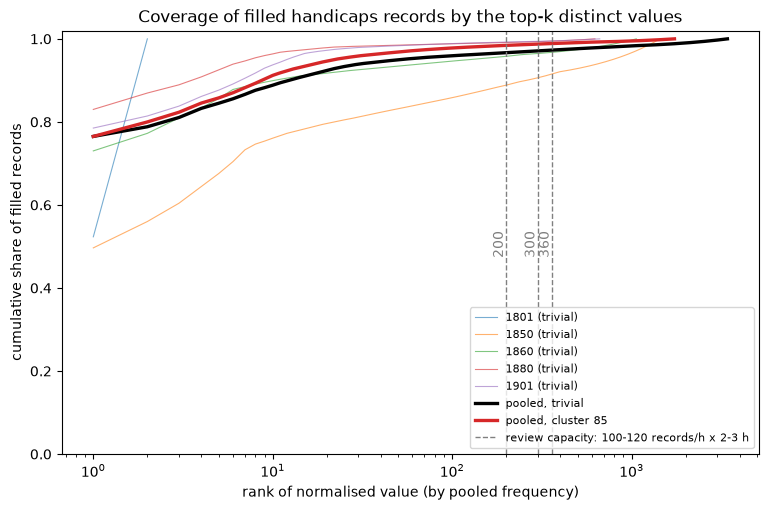

FACT task1.coverage.trivial.200=0.9667
FACT task1.coverage.cluster85.200=0.9843
FACT task1.coverage.trivial.300=0.971
FACT task1.coverage.cluster85.300=0.9875
FACT task1.coverage.trivial.360=0.973
FACT task1.coverage.cluster85.360=0.9888


level,review_values_n,coverage_share
str,i64,f64
"""trivial""",200,0.966726
"""cluster 85""",200,0.984338
"""trivial""",300,0.970967
"""cluster 85""",300,0.987507
"""trivial""",360,0.972952
"""cluster 85""",360,0.98876


In [15]:
def cum_share(counts):
    s = pl.Series(counts).sort(descending=True)
    return (s.cum_sum() / s.sum()).to_list() if s.len() else []


def coverage_at(curve, k):
    return curve[min(k, len(curve)) - 1] if curve else 0.0


curve_trivial = cum_share(NORM["n"].to_list())
curve_cluster85 = cum_share(CLUSTER85["n"].to_list())
curve_year = {
    y: cum_share(YEAR_RAW.filter(pl.col("year") == y).group_by("norm").agg(pl.col("n").sum())["n"].to_list())
    for y in YEARS
}

fig, ax = plt.subplots(figsize=(9, 5.5))
for y, c in curve_year.items():
    if c:
        ax.plot(range(1, len(c) + 1), c, lw=0.8, alpha=0.6, label=f"{y} (trivial)")
ax.plot(range(1, len(curve_trivial) + 1), curve_trivial, lw=2.4, color="black", label="pooled, trivial")
ax.plot(range(1, len(curve_cluster85) + 1), curve_cluster85, lw=2.4, color="tab:red", label="pooled, cluster 85")
for i, k in enumerate(CAPACITY_LINES):
    ax.axvline(k, color="grey", ls="--", lw=1, label="review capacity: 100-120 records/h x 2-3 h" if i == 0 else None)
    ax.text(k, 0.5, f" {k}", color="grey", rotation=90, ha="right", va="center")
ax.set_xscale("log")
ax.set_ylim(0, 1.02)
ax.set_xlabel("rank of normalised value (by pooled frequency)")
ax.set_ylabel("cumulative share of filled records")
ax.set_title("Coverage of filled handicaps records by the top-k distinct values")
ax.legend(loc="lower right", fontsize=8)
plt.show()

rows = []
for k in CAPACITY_LINES:
    ct, cc = coverage_at(curve_trivial, k), coverage_at(curve_cluster85, k)
    fact(f"task1.coverage.trivial.{k}", ct)
    fact(f"task1.coverage.cluster85.{k}", cc)
    rows.append(("trivial", k, ct))
    rows.append(("cluster 85", k, cc))
pl.DataFrame(rows, schema=["level", "review_values_n", "coverage_share"], orient="row")

This informs, but does not set, my File B impact definition. Coverage is computed on filled records only; records with an empty `handicaps` value are outside the curve and may be "not asked / not transcribed".

## Facts for open decisions

Every number below is computed above and printed as a `FACT` line (none are typed by hand). Each paragraph names the open decision it feeds and the numbers that bear on it.

In [16]:
def show_facts(*prefixes):
    for k, v in FACTS.items():
        if k.startswith(prefixes):
            print(f"FACT {k}={v}")


# derived facts for (b) and (c)
fact("task1.level2_values", FACTS["task1.distinct.trivial"])
fact("task1.leaders85.frequent", int(CLUSTER85.filter(pl.col("n") >= MIN_EXAMPLE_COUNT).height))
fact("task1.leaders85.rare", int(CLUSTER85.filter(pl.col("n") < MIN_EXAMPLE_COUNT).height))

FACT task1.level2_values=3416
FACT task1.leaders85.frequent=249
FACT task1.leaders85.rare=1483


**(a) Task 1 method.** The sizes of the three levels and the drop from one to the next: how much of the variety is spelling and punctuation (raw to trivial) and how much is near-duplicate spelling (trivial to cluster). A small remaining set favours a curated mapping; a large one favours a more automatic route.

In [17]:
show_facts("task1.distinct.", "task1.clusters.", "task1.drop.")

FACT task1.distinct.raw=4520
FACT task1.distinct.trivial=3416
FACT task1.drop.trivial_vs_raw=0.2442
FACT task1.clusters.ratio80=1472
FACT task1.drop.ratio80_vs_trivial=0.5691
FACT task1.clusters.ratio85=1732
FACT task1.drop.ratio85_vs_trivial=0.493
FACT task1.clusters.ratio90=2049
FACT task1.drop.ratio90_vs_trivial=0.4002


**(b) LLM-for-categories.** How many trivially normalised values and cluster-85 leaders a categoriser would face, and how long the singleton tail is (values seen once, and the share of filled records they represent).

In [18]:
show_facts("task1.level2_values", "task1.clusters.ratio85", "task1.multi_year_values", "task1.singleton_")

FACT task1.clusters.ratio85=1732
FACT task1.multi_year_values=307
FACT task1.singleton_values=2494
FACT task1.singleton_record_share=0.0174
FACT task1.level2_values=3416


**(c) Embedding scope.** Cluster-85 leaders with a pooled count of at least `MIN_EXAMPLE_COUNT` are candidate anchors (`frequent`); the remaining leaders are rare. These are the values that differ in wording rather than spelling and that a later wording-level grouping would have to place.

In [19]:
show_facts("task1.leaders85.")

FACT task1.leaders85.frequent=249
FACT task1.leaders85.rare=1483


**(d) File B impact.** Coverage of filled records by the top 200, 300 and 360 values at the trivial and cluster-85 levels (review capacity: 100-120 records/h x 2-3 h). The impact definition itself is left open.

In [20]:
show_facts("task1.coverage.")

FACT task1.coverage.trivial.200=0.9667
FACT task1.coverage.cluster85.200=0.9843
FACT task1.coverage.trivial.300=0.971
FACT task1.coverage.cluster85.300=0.9875
FACT task1.coverage.trivial.360=0.973
FACT task1.coverage.cluster85.360=0.9888


**(e) Missingness caveat.** Fill rate per year and the share of parishes with no filled `handicaps` value. An empty value may mean not asked or not transcribed, so these rates bound what any method can cover and say nothing about "no handicap".

In [21]:
show_facts("task1.rows.", "task1.fill_rate.", "task1.empty_parish_share.", "task1.alder_tal_parse_fail.")

FACT task1.rows.1801=937944
FACT task1.fill_rate.1801=0.0001
FACT task1.rows.1850=1405217
FACT task1.fill_rate.1850=0.0094
FACT task1.rows.1860=1748226
FACT task1.fill_rate.1860=0.0123
FACT task1.rows.1880=1979455
FACT task1.fill_rate.1880=0.0243
FACT task1.rows.1901=2468040
FACT task1.fill_rate.1901=0.0246
FACT task1.alder_tal_parse_fail.1801=0
FACT task1.alder_tal_parse_fail.1850=0
FACT task1.alder_tal_parse_fail.1860=0
FACT task1.alder_tal_parse_fail.1880=0
FACT task1.alder_tal_parse_fail.1901=0
FACT task1.empty_parish_share.1801=0.9994
FACT task1.empty_parish_share.1850=0.4304
FACT task1.empty_parish_share.1860=0.3
FACT task1.empty_parish_share.1880=0.3011
FACT task1.empty_parish_share.1901=0.3103


This notebook makes none of these decisions; I made them after this EDA.